In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [64]:
import pandas as pd

df = pd.read_excel("Dataset/Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [65]:
df.shape

(541909, 8)

In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [67]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [68]:
df.duplicated().sum()

np.int64(5268)

In [69]:
# Negative quantities
(df["Quantity"] < 0).sum()

np.int64(10624)

In [70]:
# Zero quantities
(df["Quantity"] == 0).sum()

np.int64(0)

In [71]:
# Zero or negative unit prices
(df["UnitPrice"] <= 0).sum()

np.int64(2517)

In [72]:
# Cancelled invoices
df["InvoiceNo"].astype(str).str.startswith("C").sum()

np.int64(9288)

In [73]:
df[df["Quantity"] < 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [74]:
df[df["UnitPrice"] <= 0].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom


In [75]:
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())
print("Zero or negative unit prices:", (df["UnitPrice"] <= 0).sum())
print("Cancelled invoices:", df["InvoiceNo"].astype(str).str.startswith("C").sum())

Negative quantities: 10624
Zero quantities: 0
Zero or negative unit prices: 2517
Cancelled invoices: 9288


In [76]:
clean_df = df.copy()

In [77]:
clean_df = clean_df.drop_duplicates()

print("Rows after removing duplicates:", clean_df.shape[0])

Rows after removing duplicates: 536641


In [78]:
print("Negative UnitPrice:", (clean_df["UnitPrice"] < 0).sum())
print("Zero UnitPrice:", (clean_df["UnitPrice"] == 0).sum())

Negative UnitPrice: 2
Zero UnitPrice: 2510


In [79]:
clean_df[clean_df["UnitPrice"] <= 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [80]:
clean_df[clean_df["Quantity"] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [81]:
clean_df[clean_df["UnitPrice"] <= 0][
    ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "Country"]
].head(20)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,0.0,NaN,United Kingdom


In [82]:
print(
    "Cancelled rows:",
    clean_df["InvoiceNo"].astype(str).str.startswith("C").sum()
)

Cancelled rows: 9251


In [83]:
cancel_mask = clean_df["InvoiceNo"].astype(str).str.startswith("C")
negative_qty_mask = clean_df["Quantity"] < 0

print(
    "Negative quantity + cancelled invoice:",
    (cancel_mask & negative_qty_mask).sum()
)

Negative quantity + cancelled invoice: 9251


In [84]:
print("Total negative quantity rows:",
      (clean_df["Quantity"] < 0).sum())

print("Negative quantity but NOT cancelled:",
      ((clean_df["Quantity"] < 0) &
       ~clean_df["InvoiceNo"].astype(str).str.startswith("C")).sum())

Total negative quantity rows: 10587
Negative quantity but NOT cancelled: 1336


In [85]:
clean_df[clean_df["UnitPrice"] <= 0][
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "CustomerID", "Country"]
].head(15)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,0.0,NaN,United Kingdom


In [86]:
negative_non_cancel = clean_df[
    (clean_df["Quantity"] < 0) &
    ~clean_df["InvoiceNo"].astype(str).str.startswith("C")
]

negative_non_cancel[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "CustomerID", "Country"]
].head(20)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,0.0,NaN,United Kingdom


In [87]:
negative_non_cancel["Description"].value_counts().head(15)

Description
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
??                          7
damages?                    5
wet damaged                 5
ebay                        5
smashed                     4
missing                     3
CHECK                       3
Name: count, dtype: int64

In [88]:
clean_df[clean_df["UnitPrice"] <= 0][
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "CustomerID", "Country"]
].head(20)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,0.0,NaN,United Kingdom


In [89]:
sales_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0) &
    (clean_df["Description"].notna())
].copy()

In [90]:
sales_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0) &
    (clean_df["Description"].notna())
].copy()

In [91]:
print("Clean sales rows:", sales_df.shape[0])

Clean sales rows: 524878


In [92]:
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

In [93]:
sales_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [94]:
sales_df[["Quantity", "UnitPrice", "Revenue"]].describe()

,Quantity,UnitPrice,Revenue
count,524878.000000,524878.000000,524878.000000
mean,10.616600,3.922573,20.275399
std,156.280031,36.093028,271.693566
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,3.900000
50%,4.000000,2.080000,9.920000
75%,11.000000,4.130000,17.700000
max,80995.000000,13541.330000,168469.600000


In [95]:
# Create Revenue column
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

# Create customer-level dataframe
customer_df = sales_df[sales_df["CustomerID"].notna()].copy()

# Create useful date features
sales_df["Year"] = sales_df["InvoiceDate"].dt.year
sales_df["Month"] = sales_df["InvoiceDate"].dt.month
sales_df["Month_Name"] = sales_df["InvoiceDate"].dt.month_name()
sales_df["Quarter"] = sales_df["InvoiceDate"].dt.quarter
sales_df["Day"] = sales_df["InvoiceDate"].dt.day
sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour

# Apply same date features to customer_df
customer_df["Year"] = customer_df["InvoiceDate"].dt.year
customer_df["Month"] = customer_df["InvoiceDate"].dt.month
customer_df["Month_Name"] = customer_df["InvoiceDate"].dt.month_name()
customer_df["Quarter"] = customer_df["InvoiceDate"].dt.quarter
customer_df["Day"] = customer_df["InvoiceDate"].dt.day
customer_df["Hour"] = customer_df["InvoiceDate"].dt.hour

# Summary outputs
print("Clean sales rows:", sales_df.shape[0])
print("Customer analysis rows:", customer_df.shape[0])

print("\nMissing values in sales_df:")
print(sales_df.isnull().sum())

print("\nDescriptive statistics:")
print(sales_df[["Quantity", "UnitPrice", "Revenue"]].describe())

print("\nFinal columns:")
print(sales_df.columns.tolist())

Clean sales rows: 524878
Customer analysis rows: 392692

Missing values in sales_df:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
Year                0
Month               0
Month_Name          0
Quarter             0
Day                 0
Hour                0
dtype: int64

Descriptive statistics:
            Quantity      UnitPrice        Revenue
count  524878.000000  524878.000000  524878.000000
mean       10.616600       3.922573      20.275399
std       156.280031      36.093028     271.693566
min         1.000000       0.001000       0.001000
25%         1.000000       1.250000       3.900000
50%         4.000000       2.080000       9.920000
75%        11.000000       4.130000      17.700000
max     80995.000000   13541.330000  168469.600000

Final columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Un

In [96]:
sales_df.to_csv("Dataset/Online_Retail_Cleaned.csv", index=False)

In [97]:


print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [98]:
# ==========================================
# TASK 4 - EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================

# 1. Basic Dataset Information
print("Dataset Shape:")
print(sales_df.shape)

print("\nColumn Data Types:")
print(sales_df.dtypes)

print("\nMissing Values:")
print(sales_df.isnull().sum())


# 2. Descriptive Statistics
print("\nDescriptive Statistics:")
print(
    sales_df[
        ["Quantity", "UnitPrice", "Revenue"]
    ].describe()
)


# 3. Business Summary
print("\nTotal Revenue:")
print(sales_df["Revenue"].sum())

print("\nTotal Unique Orders:")
print(sales_df["InvoiceNo"].nunique())

print("\nUnique Products:")
print(sales_df["StockCode"].nunique())

print("\nUnique Customers:")
print(sales_df["CustomerID"].nunique())

print("\nCountries:")
print(sales_df["Country"].nunique())


# 4. Correlation Analysis
numeric_columns = sales_df[
    ["Quantity", "UnitPrice", "Revenue",
     "Month", "Quarter", "Day", "Hour"]
]

correlation_matrix = numeric_columns.corr()

print("\nCorrelation Matrix:")
print(correlation_matrix.round(3))


# 5. Monthly Revenue Trend
monthly_revenue = (
    sales_df
    .groupby(["Year", "Month", "Month_Name"])["Revenue"]
    .sum()
    .reset_index()
    .sort_values(["Year", "Month"])
)

print("\nMonthly Revenue:")
print(monthly_revenue)


# 6. Top Countries by Revenue
country_revenue = (
    sales_df
    .groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 Countries by Revenue:")
print(country_revenue)


# 7. Top Products by Revenue
product_revenue = (
    sales_df
    .groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 Products by Revenue:")
print(product_revenue)


# 8. Top Products by Quantity Sold
product_quantity = (
    sales_df
    .groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 Products by Quantity Sold:")
print(product_quantity)


# 9. Outlier Detection using IQR
Q1_quantity = sales_df["Quantity"].quantile(0.25)
Q3_quantity = sales_df["Quantity"].quantile(0.75)
IQR_quantity = Q3_quantity - Q1_quantity

quantity_lower = Q1_quantity - 1.5 * IQR_quantity
quantity_upper = Q3_quantity + 1.5 * IQR_quantity

quantity_outliers = sales_df[
    (sales_df["Quantity"] < quantity_lower) |
    (sales_df["Quantity"] > quantity_upper)
]

print("\nQuantity Outliers:")
print(quantity_outliers.shape[0])


Q1_revenue = sales_df["Revenue"].quantile(0.25)
Q3_revenue = sales_df["Revenue"].quantile(0.75)
IQR_revenue = Q3_revenue - Q1_revenue

revenue_lower = Q1_revenue - 1.5 * IQR_revenue
revenue_upper = Q3_revenue + 1.5 * IQR_revenue

revenue_outliers = sales_df[
    (sales_df["Revenue"] < revenue_lower) |
    (sales_df["Revenue"] > revenue_upper)
]

print("\nRevenue Outliers:")
print(revenue_outliers.shape[0])


# 10. Customer Revenue Analysis
top_customers = (
    customer_df
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 Customers by Revenue:")
print(top_customers)

Dataset Shape:
(524878, 15)

Column Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
Revenue               float64
Year                    int32
Month                   int32
Month_Name                str
Quarter                 int32
Day                     int32
Hour                    int32
dtype: object

Missing Values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
Year                0
Month               0
Month_Name          0
Quarter             0
Day                 0
Hour                0
dtype: int64

Descriptive Statistics:
            Quantity      UnitPrice        Revenue
count  524878.000000  524878.000000  524878.000000
m

In [99]:
print(
    monthly_revenue[
        ["Year", "Month", "Month_Name", "Revenue"]
    ].to_string(index=False)
)

 Year  Month Month_Name     Revenue
 2010     12   December  821452.730
 2011      1    January  689811.610
 2011      2   February  522545.560
 2011      3      March  716215.260
 2011      4      April  536968.491
 2011      5        May  769296.610
 2011      6       June  760547.010
 2011      7       July  718076.121
 2011      8     August  757841.380
 2011      9  September 1056435.192
 2011     10    October 1151263.730
 2011     11   November 1503866.780
 2011     12   December  637790.330


In [100]:
print("Total Revenue:", round(sales_df["Revenue"].sum(), 2))
print("Total Orders:", sales_df["InvoiceNo"].nunique())

print("\nTop 5 Countries by Revenue:")
print(
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .round(2)
)

print("\nTop 5 Products by Revenue:")
print(
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .round(2)
)

# Correlation
corr = sales_df[
    ["Quantity", "UnitPrice", "Revenue", "Month", "Quarter", "Day", "Hour"]
].corr()

print("\nCorrelation with Revenue:")
print(corr["Revenue"].sort_values(ascending=False).round(3))

# Outliers using IQR
Q1_q = sales_df["Quantity"].quantile(0.25)
Q3_q = sales_df["Quantity"].quantile(0.75)
IQR_q = Q3_q - Q1_q

quantity_outliers = sales_df[
    (sales_df["Quantity"] < Q1_q - 1.5 * IQR_q) |
    (sales_df["Quantity"] > Q3_q + 1.5 * IQR_q)
]

Q1_r = sales_df["Revenue"].quantile(0.25)
Q3_r = sales_df["Revenue"].quantile(0.75)
IQR_r = Q3_r - Q1_r

revenue_outliers = sales_df[
    (sales_df["Revenue"] < Q1_r - 1.5 * IQR_r) |
    (sales_df["Revenue"] > Q3_r + 1.5 * IQR_r)
]

print("\nQuantity Outliers:", quantity_outliers.shape[0])
print("Revenue Outliers:", revenue_outliers.shape[0])

Total Revenue: 10642110.8
Total Orders: 19960

Top 5 Countries by Revenue:
Country
United Kingdom    9001744.09
Netherlands        285446.34
EIRE               283140.52
Germany            228678.40
France             209625.37
Name: Revenue, dtype: float64

Top 5 Products by Revenue:
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
Name: Revenue, dtype: float64

Correlation with Revenue:
Revenue      1.000
Quantity     0.907
UnitPrice    0.137
Month        0.000
Quarter     -0.000
Day         -0.002
Hour        -0.016
Name: Revenue, dtype: float64

Quantity Outliers: 27111
Revenue Outliers: 42624


# ==========================================
# TASK 5 - DATA VISUALIZATION
# ==========================================

In [103]:
import matplotlib.pyplot as plt

1. Monthly Revenue trend

In [105]:
import os

os.makedirs("Visualizations", exist_ok=True)

print("Visualization folder ready.")

Visualization folder ready.


In [106]:
import os
print(os.getcwd())

c:\Users\nishu\OneDrive\Desktop\InternNova-Week6-Final-Data-Analytics-Project


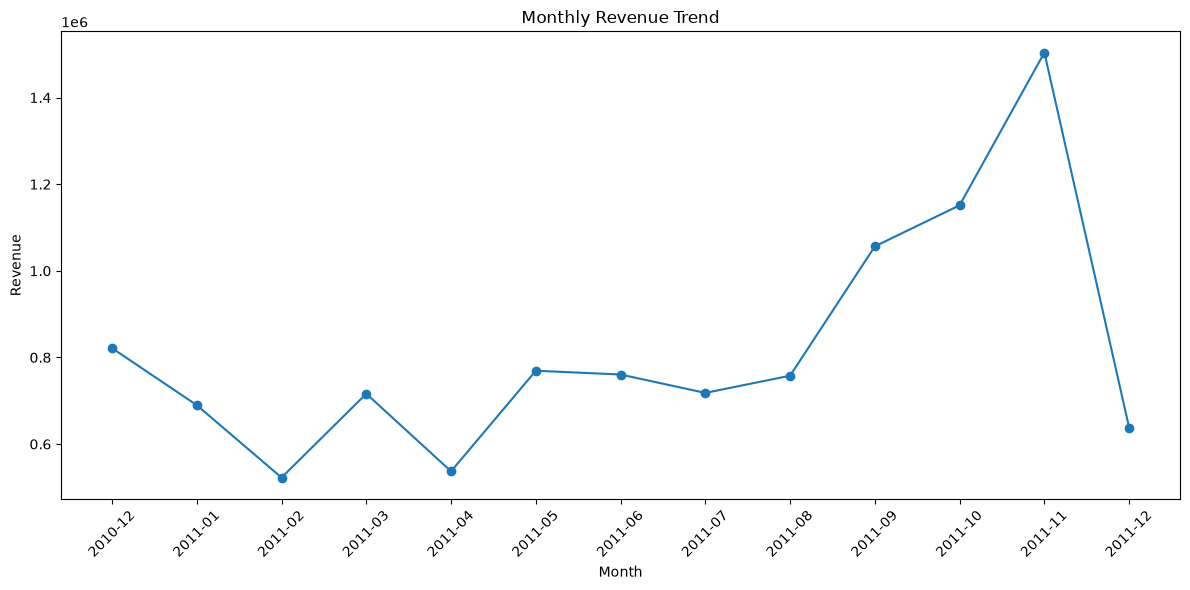

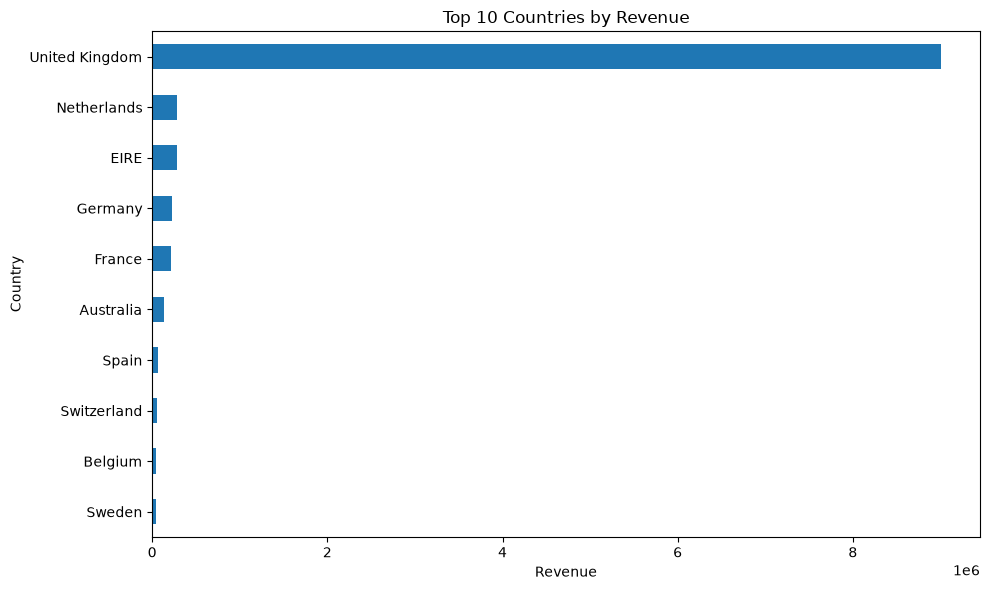

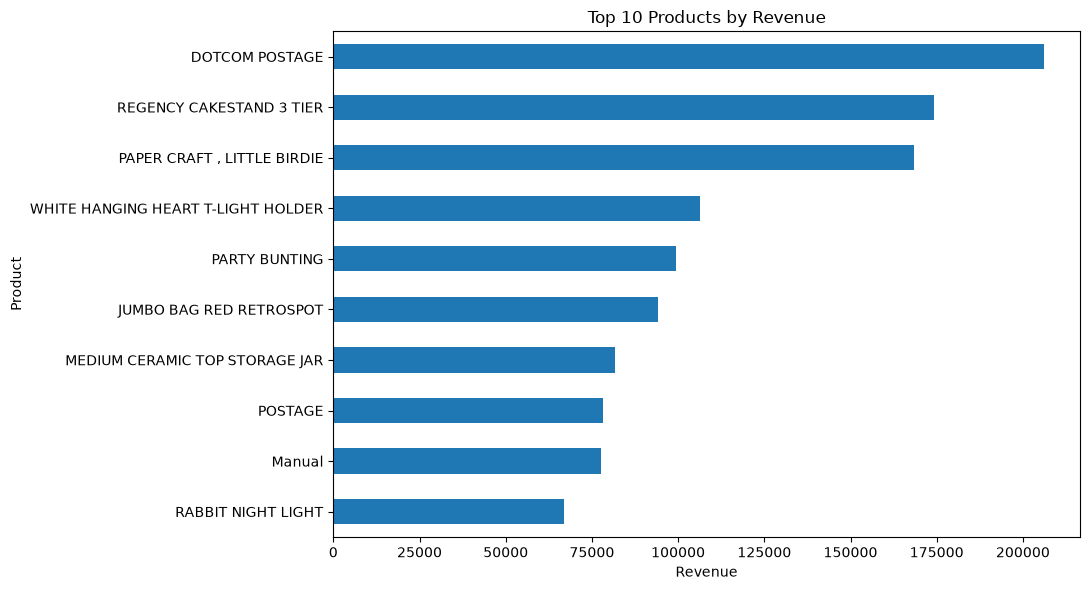

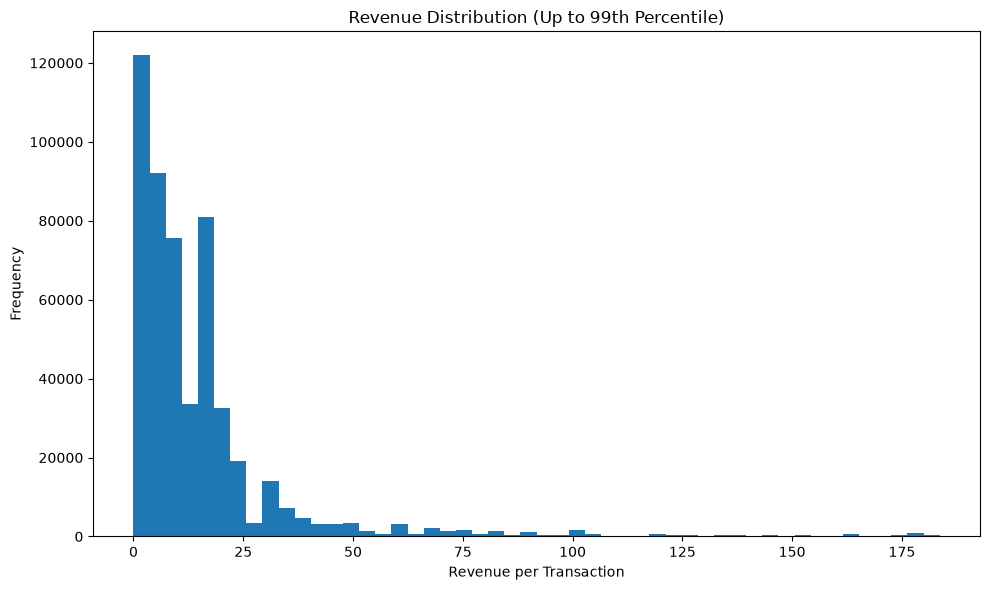

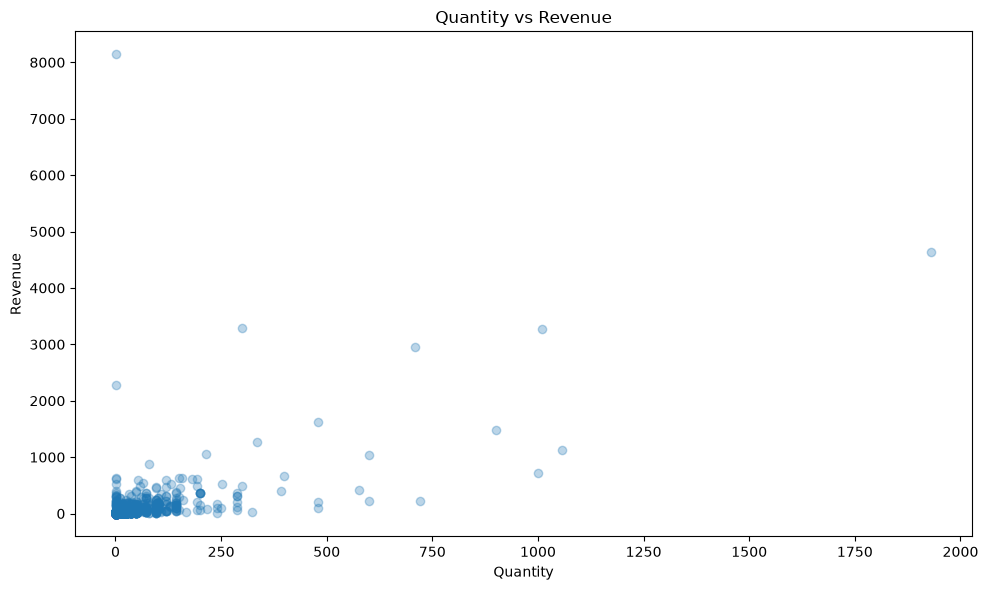

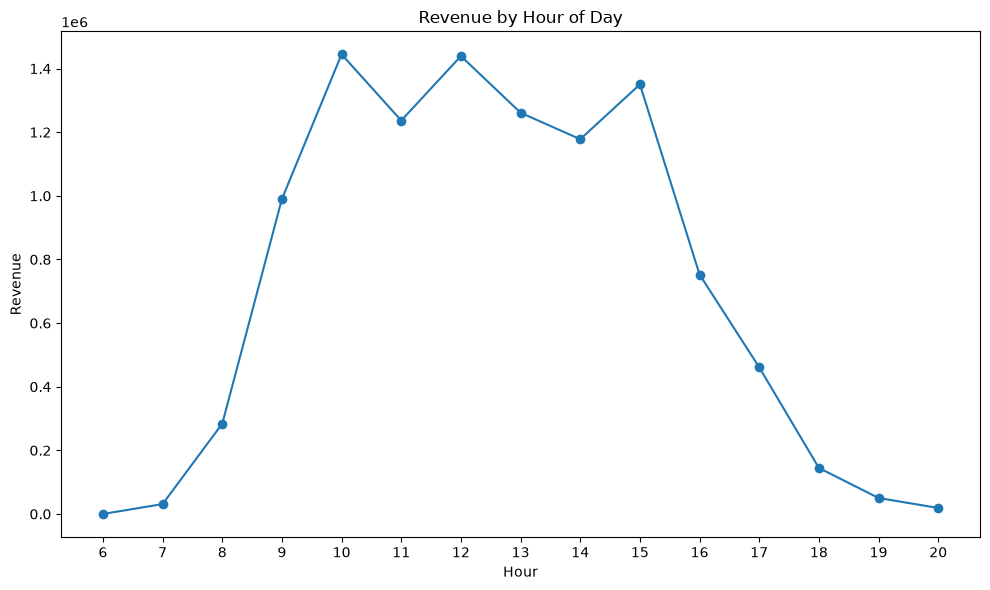

All 6 visualizations created and saved successfully.


In [107]:

monthly_chart = (
    sales_df
    .groupby(["Year", "Month", "Month_Name"])["Revenue"]
    .sum()
    .reset_index()
    .sort_values(["Year", "Month"])
)

monthly_chart["Year_Month"] = (
    monthly_chart["Year"].astype(str)
    + "-"
    + monthly_chart["Month"].astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 6))
plt.plot(
    monthly_chart["Year_Month"],
    monthly_chart["Revenue"],
    marker="o"
)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "Visualizations/01_Monthly_Revenue_Trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 2. Top 10 Countries by Revenue
top_countries = (
    sales_df
    .groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
top_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig(
    "Visualizations/02_Top_10_Countries_Revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 3. Top 10 Products by Revenue
top_products = (
    sales_df
    .groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(11, 6))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(
    "Visualizations/03_Top_10_Products_Revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 4. Revenue Distribution
revenue_99 = sales_df["Revenue"].quantile(0.99)

plt.figure(figsize=(10, 6))

plt.hist(
    sales_df.loc[
        sales_df["Revenue"] <= revenue_99,
        "Revenue"
    ],
    bins=50
)

plt.title("Revenue Distribution (Up to 99th Percentile)")
plt.xlabel("Revenue per Transaction")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    "Visualizations/04_Revenue_Distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 5. Quantity vs Revenue
scatter_sample = sales_df.sample(
    n=min(10000, len(sales_df)),
    random_state=42
)

plt.figure(figsize=(10, 6))

plt.scatter(
    scatter_sample["Quantity"],
    scatter_sample["Revenue"],
    alpha=0.3
)

plt.title("Quantity vs Revenue")
plt.xlabel("Quantity")
plt.ylabel("Revenue")
plt.tight_layout()

plt.savefig(
    "Visualizations/05_Quantity_vs_Revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# 6. Revenue by Hour
hourly_revenue = (
    sales_df
    .groupby("Hour")["Revenue"]
    .sum()
)

plt.figure(figsize=(10, 6))

plt.plot(
    hourly_revenue.index,
    hourly_revenue.values,
    marker="o"
)

plt.title("Revenue by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Revenue")
plt.xticks(hourly_revenue.index)
plt.tight_layout()

plt.savefig(
    "Visualizations/06_Revenue_by_Hour.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("All 6 visualizations created and saved successfully.")